In [1]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

df.head()

Saving retail_sales_dataset.csv to retail_sales_dataset.csv


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [2]:
# Count rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Check for missing values in each column
print("\nMissing values:")
print(df.isna().sum())

# Check for fully duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check whether transaction IDs repeat
print("Repeated transaction IDs:", df["Transaction ID"].duplicated().sum())

Rows: 1000
Columns: 9

Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0
Repeated transaction IDs: 0


In [3]:
# Convert dates; invalid dates become missing values
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Invalid dates:", df["Date"].isna().sum())
print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())

# Check for unexpected quantities or prices
print("\nZero or negative quantities:", (df["Quantity"] <= 0).sum())
print("Zero or negative prices:", (df["Price per Unit"] <= 0).sum())

# Verify that quantity × price equals the recorded total
expected_total = df["Quantity"] * df["Price per Unit"]
incorrect_totals = (expected_total - df["Total Amount"]).abs() > 0.01

print("Incorrect transaction totals:", incorrect_totals.sum())

Invalid dates: 0
Earliest date: 2023-01-01 00:00:00
Latest date: 2024-01-01 00:00:00

Zero or negative quantities: 0
Zero or negative prices: 0
Incorrect transaction totals: 0


In [4]:
print(f"Total revenue: {df['Total Amount'].sum():,.2f}")
print(f"Transactions: {len(df):,}")
print(f"Units sold: {df['Quantity'].sum():,}")
print(f"Average transaction value: {df['Total Amount'].mean():,.2f}")

# Compare revenue across product categories
category_revenue = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("\nRevenue by category:")
print(category_revenue)

Total revenue: 456,000.00
Transactions: 1,000
Units sold: 2,514
Average transaction value: 456.00

Revenue by category:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


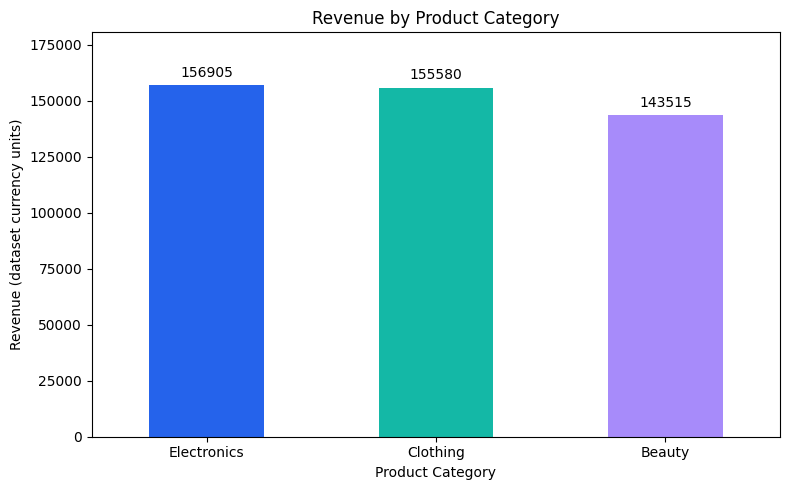

In [5]:
import matplotlib.pyplot as plt

ax = category_revenue.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#2563eb", "#14b8a6", "#a78bfa"]
)

ax.set_title("Revenue by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Revenue (dataset currency units)")
ax.tick_params(axis="x", rotation=0)

# Display each category's revenue above its bar
ax.bar_label(ax.containers[0], fmt="%.0f", padding=4)
ax.set_ylim(0, category_revenue.max() * 1.15)

plt.tight_layout()
plt.show()

Electronics contributed 34.4% of total revenue, slightly ahead of Clothing at 34.1%. Revenue was fairly evenly distributed across the three categories.

In [6]:
category_summary = df.groupby("Product Category").agg(
    Revenue=("Total Amount", "sum"),
    Units_Sold=("Quantity", "sum"),
    Transactions=("Transaction ID", "count")
)

# Average selling price, weighted by units sold
category_summary["Revenue_per_Unit"] = (
    category_summary["Revenue"] / category_summary["Units_Sold"]
)

category_summary["Average_Transaction"] = (
    category_summary["Revenue"] / category_summary["Transactions"]
)

category_summary = category_summary.sort_values(
    "Revenue", ascending=False
)

display(category_summary.round(2))

,Revenue,Units_Sold,Transactions,Revenue_per_Unit,Average_Transaction
Product Category,,,,,
Electronics,156905,849,342,184.81,458.79
Clothing,155580,894,351,174.03,443.25
Beauty,143515,771,307,186.14,467.48


,Revenue,Transactions,Units_Sold
Date,,,
2023-01,35450,76,195
2023-02,44060,85,214
2023-03,28990,73,194
2023-04,33870,86,214
2023-05,53150,105,259
2023-06,36715,77,197
2023-07,35465,72,176
2023-08,36960,94,227
2023-09,23620,65,170


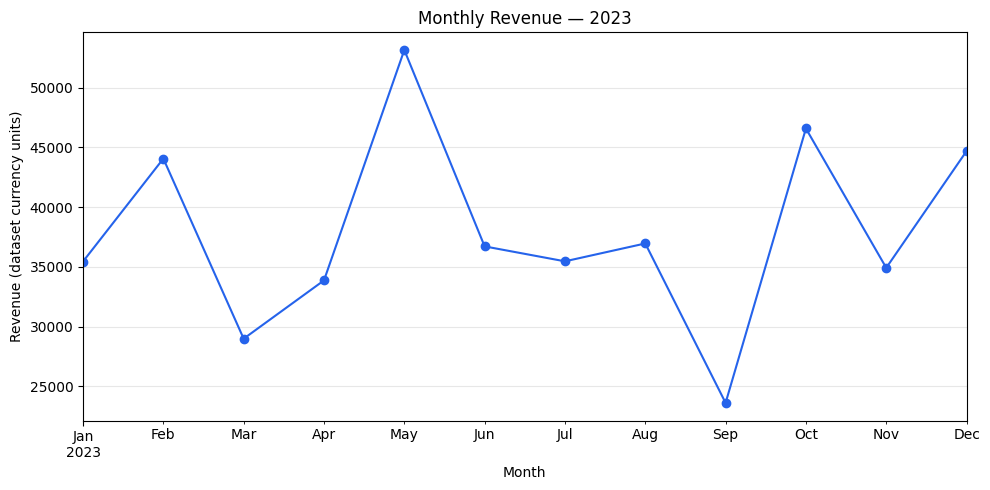

In [7]:
# Focus on 2023; January 2024 has only one day of coverage
sales_2023 = df[df["Date"].dt.year == 2023].copy()

monthly_summary = sales_2023.groupby(
    sales_2023["Date"].dt.to_period("M")
).agg(
    Revenue=("Total Amount", "sum"),
    Transactions=("Transaction ID", "count"),
    Units_Sold=("Quantity", "sum")
)

display(monthly_summary)

# Plot revenue in chronological order
ax = monthly_summary["Revenue"].plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    color="#2563eb"
)

ax.set_title("Monthly Revenue — 2023")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (dataset currency units)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

,Total Amount
Date,
2023-01,35450
2023-02,44060
2023-03,28990
2023-04,33870
2023-05,53150
2023-06,36715
2023-07,35465
2023-08,36960
2023-09,23620


Highest-revenue month: 2023-05
Lowest-revenue month: 2023-09


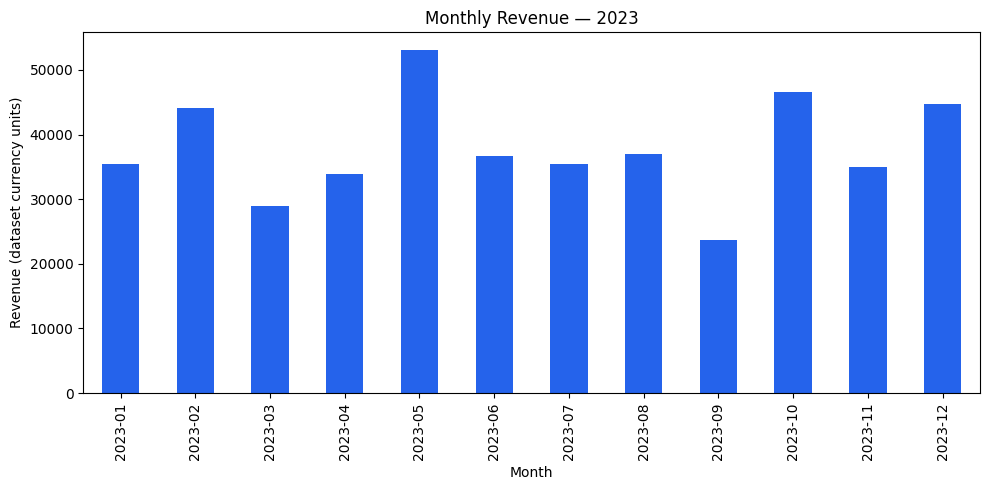

In [8]:
# Compare months within 2023 only
sales_2023 = df[df["Date"].dt.year == 2023]

monthly_revenue = sales_2023.groupby(
    sales_2023["Date"].dt.to_period("M")
)["Total Amount"].sum()

display(monthly_revenue)

print("Highest-revenue month:", monthly_revenue.idxmax())
print("Lowest-revenue month:", monthly_revenue.idxmin())

monthly_revenue.plot(
    kind="bar",
    figsize=(10, 5),
    color="#2563eb",
    title="Monthly Revenue — 2023"
)
plt.xlabel("Month")
plt.ylabel("Revenue (dataset currency units)")
plt.tight_layout()
plt.show()